# 08 — Hierarchical classification cascade

Four-level cascade that decomposes the six-mode classification problem into a sequence of simpler decisions. Each level uses a Random Forest with the same hyperparameters but a feature representation matched to the discrimination task at that level.

**Design.**

| Level | Decision | Features | Notes |
|---|---|---|---|
| L1 | Active vs Passive | Set A standard | walking+cycling vs stationary+bus+metro+tram |
| L2A | Walking vs Cycling | Set A normalized | per-session normalization handles the amplitude shift |
| L2B | Stationary vs Vehicle | Set A + event burstiness | absolute amplitude needed, plus burst features |
| L3B | Bus vs Metro vs Tram | Set A + multi-scale | 15-second context window features added |

**Baseline to beat.** Flat RF + Set A on three-day data, LOSO macro-F1 = 0.568 ± 0.064 (notebook 07).

**Evaluation.** Three internal levels (E0 random, E1 session, E2 LOSO). Two performance views:
1. Per-level macro-F1: how well each classifier does on its own task with ground-truth parent decisions.
2. End-to-end macro-F1: the full six-class cascade output, comparing apples-to-apples with notebook 07.

## 1. Imports and configuration

In [1]:
import json
import pickle
import sys
import time
import warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    StratifiedKFold, StratifiedGroupKFold, LeaveOneGroupOut,
)
from sklearn.metrics import f1_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features as F

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FEATURES_DIR  = PROJECT_ROOT / 'reports' / 'features'
RESULTS_DIR   = PROJECT_ROOT / 'reports' / 'results'
FIGURES_DIR   = PROJECT_ROOT / 'reports' / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Baseline (notebook 07, three-day data)
BASELINE_E2_MEAN = 0.568
BASELINE_E2_STD  = 0.064

## 2. Load and merge the four feature CSVs

All four files share the same row count and metadata. We merge them on `(session_id, window_index)` so each window has access to standard, normalized, event burstiness, and multi-scale features in a single DataFrame.

In [2]:
std_df  = pd.read_csv(PROCESSED_DIR / 'features_common_no_baro.csv')
norm_df = pd.read_csv(PROCESSED_DIR / 'features_common_no_baro_normalized.csv')
ext_df  = pd.read_csv(PROCESSED_DIR / 'features_common_no_baro_extended.csv')
ms_df   = pd.read_csv(PROCESSED_DIR / 'features_common_no_baro_multiscale.csv')
inventory = pd.read_csv(FEATURES_DIR / 'feature_inventory.csv')

print(f'standard:    {len(std_df)} rows x {len(std_df.columns)} cols')
print(f'normalized:  {len(norm_df)} rows x {len(norm_df.columns)} cols')
print(f'extended:    {len(ext_df)} rows x {len(ext_df.columns)} cols')
print(f'multiscale:  {len(ms_df)} rows x {len(ms_df.columns)} cols')

join_keys = ['session_id', 'window_index']
meta_cols = ['session_id', 'participant', 'mode', 'mode_id', 'day',
             'window_index', 'window_start_s', 'window_end_s', 'flagged_frac']

norm_feat_cols = [c for c in norm_df.columns if c.startswith('norm_')]
event_feat_cols = [c for c in ext_df.columns if c.startswith('event_')]
ms_feat_cols = [c for c in ms_df.columns if c.startswith('ms_')]

df = std_df.copy()
df = df.merge(norm_df[join_keys + norm_feat_cols], on=join_keys, how='inner')
df = df.merge(ext_df[join_keys + event_feat_cols], on=join_keys, how='inner')
df = df.merge(ms_df[join_keys + ms_feat_cols], on=join_keys, how='inner')

print(f'\nMerged: {len(df)} rows x {len(df.columns)} cols')
assert len(df) == len(std_df), 'Row count mismatch after merge'

standard:    14513 rows x 138 cols
normalized:  14513 rows x 138 cols
extended:    14513 rows x 150 cols
multiscale:  14513 rows x 28 cols

Merged: 14513 rows x 298 cols


## 3. Hierarchical labels

Each window receives four labels: L1 (active vs passive), and the level-2 and level-3 labels conditional on the window's true mode. Windows that do not belong to a level get -1 there and are excluded during that level's training and evaluation.

In [3]:
ACTIVE_MODES = ['walking', 'cycling']
PASSIVE_MODES = ['stationary', 'bus', 'metro', 'tram']
VEHICLE_MODES = ['bus', 'metro', 'tram']

# L1: 0 = passive, 1 = active
df['l1_label'] = df['mode'].isin(ACTIVE_MODES).astype(int)

# L2A: 0 = walking, 1 = cycling (only defined for active windows)
df['l2a_label'] = -1
df.loc[df['mode'] == 'walking', 'l2a_label'] = 0
df.loc[df['mode'] == 'cycling', 'l2a_label'] = 1

# L2B: 0 = stationary, 1 = vehicle (only defined for passive windows)
df['l2b_label'] = -1
df.loc[df['mode'] == 'stationary', 'l2b_label'] = 0
df.loc[df['mode'].isin(VEHICLE_MODES), 'l2b_label'] = 1

# L3B: 0 = bus, 1 = metro, 2 = tram (only defined for vehicle windows)
L3B_MODES = ['bus', 'metro', 'tram']
L3B_MAP = {m: i for i, m in enumerate(L3B_MODES)}
df['l3b_label'] = -1
for m, lab in L3B_MAP.items():
    df.loc[df['mode'] == m, 'l3b_label'] = lab

print('Label counts per level:')
print(f'  L1 active = {(df["l1_label"] == 1).sum()}, passive = {(df["l1_label"] == 0).sum()}')
print(f'  L2A walking = {(df["l2a_label"] == 0).sum()}, cycling = {(df["l2a_label"] == 1).sum()}')
print(f'  L2B stationary = {(df["l2b_label"] == 0).sum()}, vehicle = {(df["l2b_label"] == 1).sum()}')
for m, lab in L3B_MAP.items():
    print(f'  L3B {m} = {(df["l3b_label"] == lab).sum()}')

Label counts per level:
  L1 active = 4675, passive = 9838
  L2A walking = 2180, cycling = 2495
  L2B stationary = 2511, vehicle = 7327
  L3B bus = 2323
  L3B metro = 2549
  L3B tram = 2455


## 4. Feature sets per level

Set A is defined as `time_domain_basic + slope` (the LOSO winner from notebook 05). At L2A we use the per-session normalized variants of these features. At L2B we add event burstiness. At L3B we add multi-scale features.

In [4]:
set_a_cols = inventory.loc[
    inventory['family'].isin(['time_domain_basic', 'slope']),
    'feature'
].tolist()
set_a_cols = [c for c in set_a_cols if c in df.columns]

set_a_norm_cols = [f'norm_{c}' for c in set_a_cols if f'norm_{c}' in df.columns]

LEVEL_FEATURES = {
    'L1':  set_a_cols,
    'L2A': set_a_norm_cols,
    'L2B': set_a_cols + event_feat_cols,
    'L3B': set_a_cols + ms_feat_cols,
}

for level, cols in LEVEL_FEATURES.items():
    print(f'  {level}: {len(cols)} features')

# Sanity: all referenced columns must exist
for level, cols in LEVEL_FEATURES.items():
    missing = [c for c in cols if c not in df.columns]
    assert not missing, f'Missing columns at {level}: {missing[:5]}'

  L1: 80 features
  L2A: 80 features
  L2B: 92 features
  L3B: 99 features


## 5. CV splitters and hyperparameters

Same three evaluation levels as notebook 07. Fixed Random Forest hyperparameters across all levels: 300 trees, max_depth 20, balanced class weights. Hyperparameters are not tuned per level. The point of the experiment is the decomposition, not the tuning.

In [5]:
y_mode = df['mode_id'].values
groups_session = df['session_id'].values
groups_participant = df['participant'].values

RF_KWARGS = dict(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=1,
    class_weight='balanced',
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

def get_outer_splitter(level: str):
    if level == 'E0':
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E1':
        return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E2':
        return LeaveOneGroupOut()
    raise ValueError(level)

def get_outer_groups(level: str):
    if level == 'E0':
        return None
    if level == 'E1':
        return groups_session
    if level == 'E2':
        return groups_participant
    raise ValueError(level)

print('Hyperparameters:', RF_KWARGS)

Hyperparameters: {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 1, 'class_weight': 'balanced', 'n_jobs': -1, 'random_state': 42}


## 6. Cascade training and prediction

Train all four levels on one training set. Then run the cascade prediction: L1 first, then conditionally L2A or L2B, then conditionally L3B from L2B's vehicle branch. The final output is one mode label per window.

In [6]:
def train_cascade(train_df: pd.DataFrame) -> dict:
    """Train all four levels on the given training data. Returns dict of models."""
    models = {}

    # L1: all training data
    X = train_df[LEVEL_FEATURES['L1']].values
    y = train_df['l1_label'].values
    m = RandomForestClassifier(**RF_KWARGS)
    m.fit(X, y)
    models['L1'] = m

    # L2A: active training data only
    active = train_df[train_df['l1_label'] == 1]
    X = active[LEVEL_FEATURES['L2A']].values
    y = active['l2a_label'].values
    m = RandomForestClassifier(**RF_KWARGS)
    m.fit(X, y)
    models['L2A'] = m

    # L2B: passive training data only
    passive = train_df[train_df['l1_label'] == 0]
    X = passive[LEVEL_FEATURES['L2B']].values
    y = passive['l2b_label'].values
    m = RandomForestClassifier(**RF_KWARGS)
    m.fit(X, y)
    models['L2B'] = m

    # L3B: vehicle training data only
    vehicle = passive[passive['l2b_label'] == 1]
    X = vehicle[LEVEL_FEATURES['L3B']].values
    y = vehicle['l3b_label'].values
    m = RandomForestClassifier(**RF_KWARGS)
    m.fit(X, y)
    models['L3B'] = m

    return models


def predict_cascade(models: dict, test_df: pd.DataFrame) -> np.ndarray:
    """Run the cascade. Returns 6-class mode_id predictions, one per row."""
    n = len(test_df)
    final = np.full(n, -1, dtype=int)
    test_df = test_df.reset_index(drop=True)

    # Step 1: L1 (active vs passive)
    l1_pred = models['L1'].predict(test_df[LEVEL_FEATURES['L1']].values)

    # Active branch -> L2A
    active_mask = (l1_pred == 1)
    if active_mask.any():
        X = test_df.loc[active_mask, LEVEL_FEATURES['L2A']].values
        l2a_pred = models['L2A'].predict(X)
        # 0 = walking, 1 = cycling
        active_idx = np.where(active_mask)[0]
        final[active_idx[l2a_pred == 0]] = F.MODE_TO_ID['walking']
        final[active_idx[l2a_pred == 1]] = F.MODE_TO_ID['cycling']

    # Passive branch -> L2B
    passive_mask = (l1_pred == 0)
    if passive_mask.any():
        X = test_df.loc[passive_mask, LEVEL_FEATURES['L2B']].values
        l2b_pred = models['L2B'].predict(X)
        passive_idx = np.where(passive_mask)[0]

        # Stationary
        stat_local = (l2b_pred == 0)
        final[passive_idx[stat_local]] = F.MODE_TO_ID['stationary']

        # Vehicle branch -> L3B
        veh_local = (l2b_pred == 1)
        if veh_local.any():
            veh_idx = passive_idx[veh_local]
            X = test_df.iloc[veh_idx][LEVEL_FEATURES['L3B']].values
            l3b_pred = models['L3B'].predict(X)
            for cls, mode in enumerate(L3B_MODES):
                final[veh_idx[l3b_pred == cls]] = F.MODE_TO_ID[mode]

    # Sanity: every window should have a prediction
    assert (final >= 0).all(), 'Some windows did not receive a prediction'
    return final

## 7. Run cross-validation

For each evaluation level, iterate the outer folds. On each fold: train the full cascade on the training rows, then both (a) evaluate each level on its own task and (b) run the end-to-end cascade on the test rows. Record per-level and end-to-end macro-F1.

Expected runtime: roughly five to fifteen minutes total. Four RFs per fold and three evaluation levels combine to twenty to forty model fits.

In [7]:
EVAL_LEVELS = ('E0', 'E1', 'E2')

per_fold_rows = []
fold_predictions = {}  # level -> list of (y_true, y_pred) arrays for the end-to-end cascade
level_predictions = {}  # (eval_level, model_level) -> list of (y_true, y_pred) for per-level

for eval_level in EVAL_LEVELS:
    fold_predictions[eval_level] = []
    for ml in ('L1', 'L2A', 'L2B', 'L3B'):
        level_predictions[(eval_level, ml)] = []

    outer = get_outer_splitter(eval_level)
    g = get_outer_groups(eval_level)
    t0 = time.time()

    for fold_idx, (tr_idx, te_idx) in enumerate(outer.split(df, y_mode, groups=g)):
        train_df = df.iloc[tr_idx].copy()
        test_df  = df.iloc[te_idx].copy()

        models = train_cascade(train_df)

        # Per-level evaluation
        level_f1s = {}
        # L1 over all test windows
        l1_pred = models['L1'].predict(test_df[LEVEL_FEATURES['L1']].values)
        l1_true = test_df['l1_label'].values
        level_f1s['L1'] = f1_score(l1_true, l1_pred, average='macro')
        level_predictions[(eval_level, 'L1')].append((l1_true.copy(), l1_pred.copy()))

        # L2A on true active test windows
        active_test = test_df[test_df['l1_label'] == 1]
        if len(active_test) > 0:
            X = active_test[LEVEL_FEATURES['L2A']].values
            l2a_pred = models['L2A'].predict(X)
            l2a_true = active_test['l2a_label'].values
            level_f1s['L2A'] = f1_score(l2a_true, l2a_pred, average='macro')
            level_predictions[(eval_level, 'L2A')].append((l2a_true.copy(), l2a_pred.copy()))
        else:
            level_f1s['L2A'] = np.nan

        # L2B on true passive test windows
        passive_test = test_df[test_df['l1_label'] == 0]
        if len(passive_test) > 0:
            X = passive_test[LEVEL_FEATURES['L2B']].values
            l2b_pred = models['L2B'].predict(X)
            l2b_true = passive_test['l2b_label'].values
            level_f1s['L2B'] = f1_score(l2b_true, l2b_pred, average='macro')
            level_predictions[(eval_level, 'L2B')].append((l2b_true.copy(), l2b_pred.copy()))
        else:
            level_f1s['L2B'] = np.nan

        # L3B on true vehicle test windows
        vehicle_test = passive_test[passive_test['l2b_label'] == 1]
        if len(vehicle_test) > 0:
            X = vehicle_test[LEVEL_FEATURES['L3B']].values
            l3b_pred = models['L3B'].predict(X)
            l3b_true = vehicle_test['l3b_label'].values
            level_f1s['L3B'] = f1_score(l3b_true, l3b_pred, average='macro')
            level_predictions[(eval_level, 'L3B')].append((l3b_true.copy(), l3b_pred.copy()))
        else:
            level_f1s['L3B'] = np.nan

        # End-to-end cascade
        cascade_pred = predict_cascade(models, test_df)
        cascade_true = test_df['mode_id'].values
        cascade_f1 = f1_score(cascade_true, cascade_pred, average='macro')
        fold_predictions[eval_level].append((cascade_true.copy(), cascade_pred.copy()))

        held_out = (
            '_'.join(sorted(set(map(str, g[te_idx])))) if g is not None
            else f'fold_{fold_idx}'
        )

        per_fold_rows.append({
            'eval_level':  eval_level,
            'fold':        fold_idx,
            'held_out':    held_out,
            'l1_macro_f1': level_f1s['L1'],
            'l2a_macro_f1': level_f1s['L2A'],
            'l2b_macro_f1': level_f1s['L2B'],
            'l3b_macro_f1': level_f1s['L3B'],
            'cascade_macro_f1': float(cascade_f1),
        })

    elapsed = time.time() - t0
    f1s = [r['cascade_macro_f1'] for r in per_fold_rows if r['eval_level'] == eval_level]
    print(f'{eval_level} | cascade macro-F1 = {np.mean(f1s):.3f} +/- {np.std(f1s):.3f} | {elapsed:.0f}s')

per_fold_df = pd.DataFrame(per_fold_rows)
per_fold_df.to_csv(RESULTS_DIR / 'hierarchical_per_fold.csv', index=False)

E0 | cascade macro-F1 = 0.912 +/- 0.002 | 20s
E1 | cascade macro-F1 = 0.606 +/- 0.031 | 21s
E2 | cascade macro-F1 = 0.572 +/- 0.062 | 11s


## 8. Per-level performance summary

How well does each level perform on its own task, given ground-truth parent decisions. This is the diagnostic view that tells us where the cascade succeeds and where it leaks.

In [8]:
summary_rows = []
for level in EVAL_LEVELS:
    sub = per_fold_df[per_fold_df['eval_level'] == level]
    row = {'eval_level': level}
    for col in ('l1_macro_f1', 'l2a_macro_f1', 'l2b_macro_f1', 'l3b_macro_f1',
                'cascade_macro_f1'):
        row[col + '_mean'] = float(sub[col].mean())
        row[col + '_std']  = float(sub[col].std())
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / 'hierarchical_summary.csv', index=False)

print('Per-level macro-F1 (mean +/- std across folds):')
for _, r in summary_df.iterrows():
    print(f'\n{r["eval_level"]}:')
    for ml, name in [('l1', 'L1 (Active vs Passive)'),
                      ('l2a', 'L2A (Walking vs Cycling)'),
                      ('l2b', 'L2B (Stationary vs Vehicle)'),
                      ('l3b', 'L3B (Bus vs Metro vs Tram)'),
                      ('cascade', 'End-to-end cascade')]:
        m = r[f'{ml}_macro_f1_mean']
        s = r[f'{ml}_macro_f1_std']
        print(f'  {name:32s}: {m:.3f} +/- {s:.3f}')

Per-level macro-F1 (mean +/- std across folds):

E0:
  L1 (Active vs Passive)          : 0.990 +/- 0.002
  L2A (Walking vs Cycling)        : 0.990 +/- 0.003
  L2B (Stationary vs Vehicle)     : 0.965 +/- 0.007
  L3B (Bus vs Metro vs Tram)      : 0.874 +/- 0.007
  End-to-end cascade              : 0.912 +/- 0.002

E1:
  L1 (Active vs Passive)          : 0.986 +/- 0.006
  L2A (Walking vs Cycling)        : 0.884 +/- 0.094
  L2B (Stationary vs Vehicle)     : 0.725 +/- 0.164
  L3B (Bus vs Metro vs Tram)      : 0.497 +/- 0.090
  End-to-end cascade              : 0.606 +/- 0.035

E2:
  L1 (Active vs Passive)          : 0.975 +/- 0.020
  L2A (Walking vs Cycling)        : 0.748 +/- 0.128
  L2B (Stationary vs Vehicle)     : 0.742 +/- 0.214
  L3B (Bus vs Metro vs Tram)      : 0.514 +/- 0.020
  End-to-end cascade              : 0.572 +/- 0.076


## 9. Cascade versus flat baseline

The headline comparison. Cascade end-to-end macro-F1 against the flat RF + Set A baseline from notebook 07.

In [9]:
cascade_e2_mean = float(per_fold_df.loc[per_fold_df['eval_level'] == 'E2', 'cascade_macro_f1'].mean())
cascade_e2_std  = float(per_fold_df.loc[per_fold_df['eval_level'] == 'E2', 'cascade_macro_f1'].std())

delta = cascade_e2_mean - BASELINE_E2_MEAN
noise_floor = max(cascade_e2_std, BASELINE_E2_STD)

if delta > noise_floor:
    verdict = 'improves over flat baseline'
elif abs(delta) <= noise_floor:
    verdict = 'matches flat baseline (within noise)'
else:
    verdict = 'underperforms flat baseline'

print(f'Flat RF + Set A on E2:    {BASELINE_E2_MEAN:.3f} +/- {BASELINE_E2_STD:.3f}')
print(f'Cascade on E2:            {cascade_e2_mean:.3f} +/- {cascade_e2_std:.3f}')
print(f'Delta: {delta:+.3f}  | noise floor: {noise_floor:.3f}')
print(f'Verdict: cascade {verdict}')

Flat RF + Set A on E2:    0.568 +/- 0.064
Cascade on E2:            0.572 +/- 0.076
Delta: +0.004  | noise floor: 0.076
Verdict: cascade matches flat baseline (within noise)


## 10. End-to-end confusion matrix

Six-class confusion matrix for the cascade on E2, concatenated across the three LOSO folds. Directly comparable to `cm_loso_rf_three_days.png` from notebook 07.

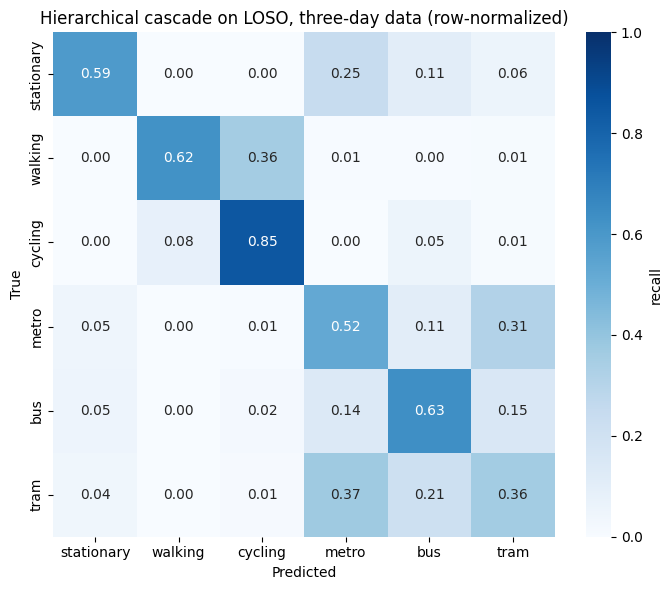

Saved: C:\Projects\this project-transport-mode\reports\figures\cm_loso_hierarchical.png


In [10]:
y_true_all = np.concatenate([p[0] for p in fold_predictions['E2']])
y_pred_all = np.concatenate([p[1] for p in fold_predictions['E2']])

cm = confusion_matrix(y_true_all, y_pred_all, labels=list(range(len(F.MODES))))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=F.MODES, yticklabels=F.MODES, ax=ax,
    cbar_kws={'label': 'recall'}, vmin=0, vmax=1,
)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Hierarchical cascade on LOSO, three-day data (row-normalized)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'cm_loso_hierarchical.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f'Saved: {FIGURES_DIR / "cm_loso_hierarchical.png"}')

## 11. Per-class F1: cascade versus flat baseline

Side-by-side per-mode F1 to see where the cascade helped and where it hurt. The two-day baseline numbers from notebook 07 are hard-coded for the visual comparison.

In [11]:
cascade_per_class = f1_score(
    y_true_all, y_pred_all,
    labels=list(range(len(F.MODES))), average=None,
)

# Flat baseline per-class F1 on E2 from notebook 07 section 10
flat_per_class = {
    'stationary': 0.736, 'walking': 0.721, 'cycling': 0.778,
    'metro': 0.432, 'bus': 0.563, 'tram': 0.394,
}

compare_rows = []
for cls_id, mode in enumerate(F.MODES):
    compare_rows.append({
        'mode':         mode,
        'flat_f1':      flat_per_class[mode],
        'cascade_f1':   float(cascade_per_class[cls_id]),
        'delta':        float(cascade_per_class[cls_id]) - flat_per_class[mode],
    })
compare_df = pd.DataFrame(compare_rows)
compare_df.to_csv(RESULTS_DIR / 'hierarchical_per_class_comparison.csv', index=False)

print('Per-class F1 on LOSO (flat baseline vs cascade):')
print(compare_df.round(3).to_string(index=False))

Per-class F1 on LOSO (flat baseline vs cascade):
      mode  flat_f1  cascade_f1  delta
stationary    0.736       0.682 -0.054
   walking    0.721       0.724  0.003
   cycling    0.778       0.772 -0.006
     metro    0.432       0.464  0.032
       bus    0.563       0.587  0.024
      tram    0.394       0.377 -0.017


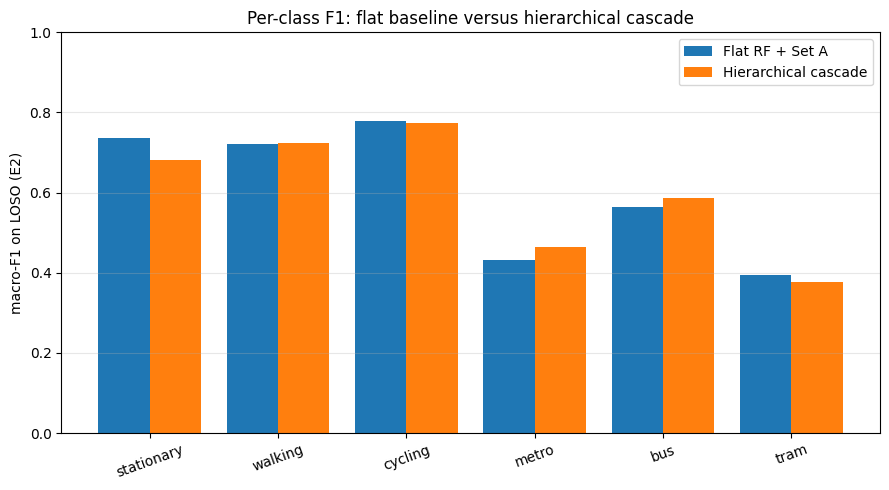

Saved: C:\Projects\this project-transport-mode\reports\figures\per_class_flat_vs_hierarchical.png


In [12]:
# Side-by-side bar chart
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(F.MODES))
w = 0.4
ax.bar(x - w/2, compare_df['flat_f1'], width=w, label='Flat RF + Set A')
ax.bar(x + w/2, compare_df['cascade_f1'], width=w, label='Hierarchical cascade')
ax.set_xticks(x)
ax.set_xticklabels(F.MODES, rotation=20)
ax.set_ylabel('macro-F1 on LOSO (E2)')
ax.set_title('Per-class F1: flat baseline versus hierarchical cascade')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'per_class_flat_vs_hierarchical.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f'Saved: {FIGURES_DIR / "per_class_flat_vs_hierarchical.png"}')

## 12. Per-level confusion matrices on LOSO

Each classifier's confusion matrix on its own task, with ground-truth parent decisions. Shows where each level individually succeeds and fails, before any cascade error propagation.

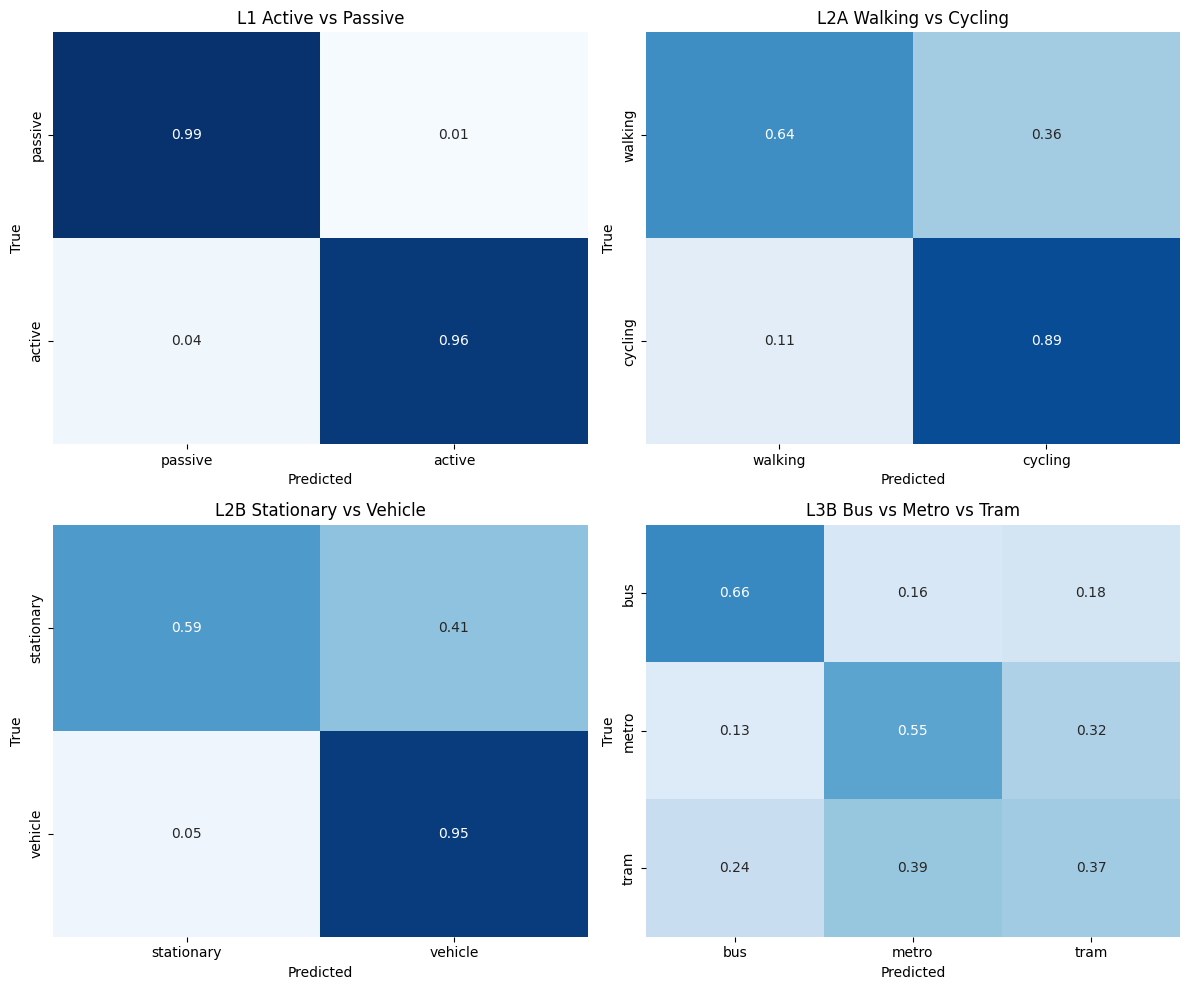

Saved: C:\Projects\this project-transport-mode\reports\figures\cm_loso_per_level.png


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
level_info = [
    ('L1',  axes[0,0], ['passive', 'active'], 'L1 Active vs Passive'),
    ('L2A', axes[0,1], ['walking', 'cycling'], 'L2A Walking vs Cycling'),
    ('L2B', axes[1,0], ['stationary', 'vehicle'], 'L2B Stationary vs Vehicle'),
    ('L3B', axes[1,1], L3B_MODES, 'L3B Bus vs Metro vs Tram'),
]

for ml, ax, labels, title in level_info:
    preds = level_predictions[('E2', ml)]
    if not preds:
        ax.set_title(f'{title}: no data')
        continue
    y_t = np.concatenate([p[0] for p in preds])
    y_p = np.concatenate([p[1] for p in preds])
    cm = confusion_matrix(y_t, y_p, labels=list(range(len(labels))))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=labels, yticklabels=labels, ax=ax,
        cbar=False, vmin=0, vmax=1,
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'cm_loso_per_level.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f'Saved: {FIGURES_DIR / "cm_loso_per_level.png"}')

## 13. Barometer ablation on L3B (Babis + Xiomara subset)

Athina's phone lacks a barometer, so the main cascade uses no pressure features anywhere. As a side experiment, we evaluate Level 3B with four added barometer features (pressure mean, range, std, slope) on the subset of windows from participants who do have barometer data.

If pressure helps separate metro (underground, descending) from bus and tram (street level), the Level 3B F1 should improve substantially on this subset.

If no barometer data is found in the interim files, this section is skipped.

In [14]:
from src.data_loading import build_session_index
from src.features import iterate_windows, derive_magnitudes

INTERIM_DIR = PROJECT_ROOT / 'data' / 'interim'
session_index = build_session_index(INTERIM_DIR)

BARO_PARTICIPANTS = ['babis', 'xiomara']  # those with barometer

def has_pressure(session_path):
    df = pd.read_csv(session_path, nrows=3)
    return 'pressure' in df.columns

baro_available = any(
    has_pressure(s['path']) for s in session_index
    if s['participant'] in BARO_PARTICIPANTS and s['mode'] in F.MODES
)
print(f'Barometer data found in interim files: {baro_available}')

Barometer data found in interim files: True


In [15]:
def compute_pressure_features(window_df: pd.DataFrame) -> dict:
    """Four pressure features for the barometer ablation."""
    arr = window_df['pressure'].values.astype(float)
    n = len(arr)
    out = {
        'baro_mean':  float(np.mean(arr)),
        'baro_range': float(np.max(arr) - np.min(arr)),
        'baro_std':   float(np.std(arr)),
    }
    # Linear slope over the window
    if n >= 2:
        x = np.arange(n, dtype=float)
        denom = float(np.sum((x - x.mean()) ** 2))
        if denom > 1e-12:
            slope = float(np.sum((x - x.mean()) * (arr - arr.mean())) / denom)
        else:
            slope = 0.0
    else:
        slope = 0.0
    out['baro_slope'] = slope
    return out


if baro_available:
    baro_rows = []
    for sess in session_index:
        if sess['participant'] not in BARO_PARTICIPANTS:
            continue
        if sess['mode'] not in VEHICLE_MODES:
            continue
        sdf = pd.read_csv(sess['path']).reset_index(drop=True)
        if 'pressure' not in sdf.columns:
            continue
        has_bad = 'bad_sample' in sdf.columns
        for w_idx, (s, e) in enumerate(iterate_windows(len(sdf))):
            if has_bad and bool(sdf.iloc[s:e]['bad_sample'].any()):
                continue
            window = sdf.iloc[s:e]
            try:
                bf = compute_pressure_features(window)
            except Exception:
                continue
            baro_rows.append({
                'session_id':  sess['session_id'],
                'window_index': w_idx,
                **bf,
            })
    baro_df = pd.DataFrame(baro_rows)
    print(f'Barometer features computed for {len(baro_df)} vehicle windows')
else:
    baro_df = None
    print('Skipping barometer ablation')

Barometer features computed for 4730 vehicle windows


In [16]:
if baro_available and baro_df is not None and len(baro_df) > 0:
    # Subset the main DataFrame to vehicle windows for Babis + Xiomara
    vehicle_sub = df[
        (df['participant'].isin(BARO_PARTICIPANTS)) &
        (df['mode'].isin(VEHICLE_MODES))
    ].copy()
    vehicle_sub = vehicle_sub.merge(
        baro_df, on=['session_id', 'window_index'], how='inner'
    )
    print(f'Vehicle windows (Babis+Xiomara, with barometer): {len(vehicle_sub)}')

    baro_cols = ['baro_mean', 'baro_range', 'baro_std', 'baro_slope']
    set_a_plus_ms = LEVEL_FEATURES['L3B']
    set_a_plus_ms_plus_baro = set_a_plus_ms + baro_cols

    # Leave-one-subject-out on the two participants
    loso = LeaveOneGroupOut()
    groups_sub = vehicle_sub['participant'].values
    y_sub = vehicle_sub['l3b_label'].values

    baro_results = []
    for variant_name, variant_cols in [
        ('imu_only', set_a_plus_ms),
        ('imu_plus_baro', set_a_plus_ms_plus_baro),
    ]:
        for fold_idx, (tr_idx, te_idx) in enumerate(
            loso.split(vehicle_sub, y_sub, groups=groups_sub)
        ):
            X_tr = vehicle_sub.iloc[tr_idx][variant_cols].values
            y_tr = vehicle_sub.iloc[tr_idx]['l3b_label'].values
            X_te = vehicle_sub.iloc[te_idx][variant_cols].values
            y_te = vehicle_sub.iloc[te_idx]['l3b_label'].values
            held_out = groups_sub[te_idx][0]

            m = RandomForestClassifier(**RF_KWARGS)
            m.fit(X_tr, y_tr)
            y_pr = m.predict(X_te)
            macro_f1 = f1_score(y_te, y_pr, average='macro')

            baro_results.append({
                'variant':  variant_name,
                'held_out': held_out,
                'macro_f1': float(macro_f1),
                'n_features': len(variant_cols),
            })
    baro_df_res = pd.DataFrame(baro_results)
    baro_df_res.to_csv(RESULTS_DIR / 'hierarchical_baro_ablation.csv', index=False)
    print('\nL3B barometer ablation results (Babis+Xiomara subset, leave-one-out):')
    print(baro_df_res.to_string(index=False))
    print('\nMean by variant:')
    print(baro_df_res.groupby('variant')['macro_f1'].agg(['mean', 'std']).round(3))
else:
    print('Barometer ablation skipped (no pressure data available)')

Vehicle windows (Babis+Xiomara, with barometer): 4730

L3B barometer ablation results (Babis+Xiomara subset, leave-one-out):
      variant held_out  macro_f1  n_features
     imu_only    babis  0.503790          99
     imu_only  xiomara  0.491148          99
imu_plus_baro    babis  0.531843         103
imu_plus_baro  xiomara  0.523764         103

Mean by variant:
                mean    std
variant                    
imu_only       0.497  0.009
imu_plus_baro  0.528  0.006


## 14. Save the cascade pipeline

Refit the full cascade on all data using the same hyperparameters. Save with the level definitions and feature lists so notebook 09 can apply the cascade to external participants without re-implementing the prediction logic.

In [17]:
final_models = train_cascade(df)

artefact = {
    'models':           final_models,
    'level_features':   LEVEL_FEATURES,
    'rf_kwargs':        RF_KWARGS,
    'mode_to_id':       F.MODE_TO_ID,
    'l3b_modes':        L3B_MODES,
    'l3b_map':          L3B_MAP,
    'active_modes':     ACTIVE_MODES,
    'vehicle_modes':    VEHICLE_MODES,
    'cascade_e2_mean':  cascade_e2_mean,
    'cascade_e2_std':   cascade_e2_std,
    'flat_baseline':    BASELINE_E2_MEAN,
}
with open(RESULTS_DIR / 'hierarchical_cascade.pkl', 'wb') as f:
    pickle.dump(artefact, f)
print(f'Saved: {RESULTS_DIR / "hierarchical_cascade.pkl"}')

Saved: C:\Projects\this project-transport-mode\reports\results\hierarchical_cascade.pkl


## 15. Summary

Artifacts produced:
- `hierarchical_per_fold.csv`: per-fold per-level macro-F1 and cascade macro-F1.
- `hierarchical_summary.csv`: aggregated per-level performance.
- `hierarchical_per_class_comparison.csv`: per-mode F1 versus flat baseline.
- `hierarchical_baro_ablation.csv`: L3B with and without barometer, Babis+Xiomara subset.
- `cm_loso_hierarchical.png`: end-to-end cascade confusion matrix.
- `cm_loso_per_level.png`: four-panel per-level confusion matrices.
- `per_class_flat_vs_hierarchical.png`: side-by-side bar chart.
- `hierarchical_cascade.pkl`: refit cascade for notebook 09 (external validation).

Reading order for the report write-up:
1. Headline number from section 9 (cascade vs flat baseline on E2).
2. Per-class comparison from section 11 (which modes improved, which did not).
3. End-to-end confusion matrix from section 10 versus the flat one from notebook 07.
4. Per-level diagnostics from section 12 (where each classifier succeeds and leaks).
5. Barometer side experiment from section 13 (concrete evidence that pressure helps metro).